In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
import cooler
import cooltools
from scipy.optimize import curve_fit
from scipy.stats import pearsonr
from matplotlib.colors import to_rgb
from matplotlib.lines import Line2D

def func_linear(x, k, m):
    return k*x + m

/exports/igmm/eddie/chr11/elias/anaconda/envs/cool/lib/python3.8/site-packages/requests/__init__.py:102: RequestsDependencyWarning: urllib3 (1.26.8) or chardet (5.1.0)/charset_normalizer (2.0.11) doesn't match a supported version!
  warnings.warn("urllib3 ({}) or chardet ({})/charset_normalizer ({}) doesn't match a supported "


In [2]:
def generate_virtual_4c(coolers_dict, chrom, viewpoint, view_limits, resolution, regions_dict=None):
    vp_region = (chrom, viewpoint[0], viewpoint[1])
    lim_region = (chrom, view_limits[0], view_limits[1])
    
    tracks = []
    for name, clr in coolers_dict.items():
        bins = clr.bins().fetch(lim_region).copy()
        mat = clr.matrix(balance='weight').fetch(vp_region, lim_region)
        mat = np.nan_to_num(mat)
        profile = np.sum(mat, axis=0)
        bins['value'] = profile
        bins['sample'] = name
        tracks.append(bins)
        
    tracks_df = pd.concat(tracks, ignore_index=True)
    
    tracks_df['log_value'] = np.where(tracks_df['value'] > 0, 
                                      np.log(tracks_df['value']), 
                                      0)
    
    tracks_df['target_region'] = ""
    
    if regions_dict:
        for region_name, (r_start, r_end) in regions_dict.items():
            overlap_mask = (tracks_df['end'] > r_start) & (tracks_df['start'] < r_end)
            tracks_df.loc[overlap_mask, 'target_region'] = region_name
    
    return tracks_df

In [3]:
def calculate_v4c_fold_change(v4c_df, baseline_cond, test_cond, regions_dict, pseudocount=1e-6, column='value'):
    results = []
    for region_name, (start, end) in regions_dict.items():
        region_overlap = v4c_df[(v4c_df['end'] > start) & (v4c_df['start'] < end)]
        sum_baseline = region_overlap[region_overlap['sample'] == baseline_cond][column].sum()
        sum_test = region_overlap[region_overlap['sample'] == test_cond][column].sum()
        fc = (sum_test + pseudocount) / (sum_baseline + pseudocount)
        log2_fc = np.log2(fc)
        
        results.append({
            "Region": region_name,
            "Coordinates": f"{start}-{end}",
            f"baseline_contacts": sum_baseline,
            f"test_contacts": sum_test,
            f"FoldChange": fc,
            "Condition": f"{test_cond}/{baseline_cond}",
        })
        
    return pd.DataFrame(results)

In [4]:
resolution=10000

In [5]:
#RCMC files can be downloaded from: 
#https://www.ncbi.nlm.nih.gov/geo/download/?acc=GSE329685&format=file
#https://www.ncbi.nlm.nih.gov/geo/download/?acc=GSE329685&format=file&file=GSE329685%5FRCMC%5FWAPL%2DdTAG%5FDMSO%2Echr5%5FShhmGL%2Emapq%5F30%2E1000%2Emcool
#https://www.ncbi.nlm.nih.gov/geo/download/?acc=GSE329685&format=file&file=GSE329685%5FRCMC%5FWAPL%2DdTAG%5FdTAG%2Echr5%5FShhmGL%2Emapq%5F30%2E1000%2Emcool
#https://www.ncbi.nlm.nih.gov/geo/download/?acc=GSE329685&format=file&file=GSE329685%5FRCMC%5FdTAG%2DNIPBL%5FDMSO%2Echr5%5FShhmGL%2Emapq%5F30%2E1000%2Emcool
#https://www.ncbi.nlm.nih.gov/geo/download/?acc=GSE329685&format=file&file=GSE329685%5FRCMC%5FdTAG%2DNIPBL%5FdTAG%2Echr5%5FShhmGL%2Emapq%5F30%2E1000%2Emcool

In [6]:
NIPBL = cooler.Cooler(f'GSE329685_RCMC_dTAG-NIPBL_DMSO.chr5_ShhmGL.mapq_30.1000.mcool::/resolutions/{resolution}')
NIPBL_deg = cooler.Cooler(f'GSE329685_RCMC_dTAG-NIPBL_dTAG.chr5_ShhmGL.mapq_30.1000.mcool::/resolutions/{resolution}')

In [7]:
WAPL = cooler.Cooler(f'GSE329685_RCMC_WAPL-dTAG_DMSO.chr5_ShhmGL.mapq_30.1000.mcool::/resolutions/{resolution}')
WAPL_deg = cooler.Cooler(f'GSE329685_RCMC_WAPL-dTAG_dTAG.chr5_ShhmGL.mapq_30.1000.mcool::/resolutions/{resolution}')

In [8]:
NIPBL0 = cooler.Cooler(f'GSM9709004_RCMC_dTAG-NIPBL_dTAG_0nM.chr5_ShhmGL.mapq_30.1000.mcool::/resolutions/{resolution}')
NIPBL2 = cooler.Cooler(f'GSM9709005_RCMC_dTAG-NIPBL_dTAG_2nM.chr5_ShhmGL.mapq_30.1000.mcool::/resolutions/{resolution}')
NIPBL5 = cooler.Cooler(f'GSM9709006_RCMC_dTAG-NIPBL_dTAG_5nM.chr5_ShhmGL.mapq_30.1000.mcool::/resolutions/{resolution}')
NIPBL10 = cooler.Cooler(f'GSM9709007_RCMC_dTAG-NIPBL_dTAG_10nM.chr5_ShhmGL.mapq_30.1000.mcool::/resolutions/{resolution}')
NIPBL250 = cooler.Cooler(f'GSM9709008_RCMC_dTAG-NIPBL_dTAG_250nM.chr5_ShhmGL.mapq_30.1000.mcool::/resolutions/{resolution}')

In [9]:
chrom = 'chr5_ShhmGL'
shh_viewpoint = (28_456_800, 28_466_800)
limit_view = (28400000, 29430000)
              
target_regions = {
    "96": (28562975, 28564060),
    "206": (28672720, 28673697),
    "409": (28875218, 28876862),
    "848": (29314358, 29316254),
}

#Note that all coordinates after Shh CDS end are shifted by -8140bp due to the repacement of Shh with mGL
offset = 8140

target_regions = {
    key: (start - offset, end - offset) 
    for key, (start, end) in target_regions.items()
}

coolers = {
    "NIPBL+": NIPBL, 
    "NIPBL-": NIPBL_deg,
    "NIPBL0": NIPBL0, 
    "NIPBL2": NIPBL2,
    "NIPBL5": NIPBL5, 
    "NIPBL10": NIPBL10,
    "NIPBL250": NIPBL250, 
    "WAPL+": WAPL,
    "WAPL-": WAPL_deg,
}


v4c_data = generate_virtual_4c(
    coolers_dict = coolers,
    chrom = chrom,
    viewpoint = shh_viewpoint,
    view_limits = limit_view,
    resolution = resolution,
    regions_dict = target_regions
)

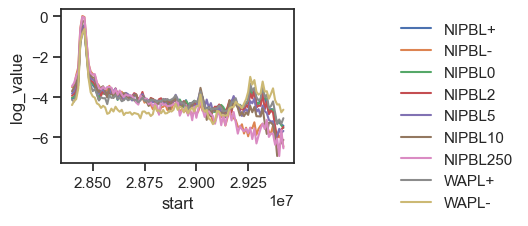

In [10]:
sns.set(style="ticks", font="Arial", rc={'figure.figsize':(3,2)}, font_scale=1)
g = sns.lineplot(data = v4c_data, x = "start", y = "log_value", 
                  hue = "sample",
                  legend=True)
sns.move_legend(obj=g, loc="upper right", bbox_to_anchor=(2,1), frameon=False, title="")

In [11]:
nipbl_results = calculate_v4c_fold_change(
    v4c_df = v4c_data, 
    baseline_cond = "NIPBL+", 
    test_cond = "NIPBL-", 
    regions_dict = target_regions,
    column="value"
)

wapl_results = calculate_v4c_fold_change(
    v4c_df = v4c_data, 
    baseline_cond = "WAPL+", 
    test_cond = "WAPL-", 
    regions_dict = target_regions,
    column="value"
)

dose2_results = calculate_v4c_fold_change(
    v4c_df = v4c_data, 
    baseline_cond = "NIPBL0", 
    test_cond = "NIPBL2", 
    regions_dict = target_regions,
    column="value"
)

dose5_results = calculate_v4c_fold_change(
    v4c_df = v4c_data, 
    baseline_cond = "NIPBL0", 
    test_cond = "NIPBL5", 
    regions_dict = target_regions,
    column="value"
)

dose10_results = calculate_v4c_fold_change(
    v4c_df = v4c_data, 
    baseline_cond = "NIPBL0", 
    test_cond = "NIPBL10", 
    regions_dict = target_regions,
    column="value"
)

In [12]:
fc_results = pd.concat([nipbl_results, wapl_results, dose2_results, dose5_results, dose10_results])

In [13]:
Shh_flow_FC1 = pd.concat([
    pd.read_table("NIPBL_data_FC_1.txt"),
    pd.read_table("NIPBL_data_FC_3.txt"),
    pd.read_table("WAPL_data_FC_1.txt"),
    pd.read_table("WAPL_data_FC_3.txt"),
    ])
Shh_flow_FC1 = Shh_flow_FC1[Shh_flow_FC1["treatment"]=="dTAG"]
Shh_flow_FC1["Condition"] = np.where(Shh_flow_FC1["cell_line"]=="dTAG-NIPBL", "NIPBL-/NIPBL+", "WAPL-/WAPL+")
Shh_flow_FC2 = pd.concat([
    pd.read_table("NIPBL_data_FC_2.txt"),
    pd.read_table("WAPL_data_FC_2.txt"),
    ])
Shh_flow_FC2 = Shh_flow_FC2[Shh_flow_FC2["dose"] >= 1]
Shh_flow_FC2["dose"] = Shh_flow_FC2["dose"].astype(int).astype(str)
Shh_flow_FC2["Condition"] = np.where(Shh_flow_FC2["cell_line"]=="dTAG-NIPBL", "NIPBL" + Shh_flow_FC2["dose"] + "/NIPBL0", "WAPL" + Shh_flow_FC2["dose"] + "/WAPL0")
Shh_flow_FC2["Condition"] = np.where(Shh_flow_FC2["Condition"]=="NIPBL250/NIPBL0", "NIPBL-/NIPBL+", 
                                  np.where(Shh_flow_FC2["Condition"]=="WAPL250/WAPL0", "WAPL-/WAPL+", Shh_flow_FC2["Condition"]))
Shh_flow_FC = pd.concat([Shh_flow_FC1, Shh_flow_FC2]).rename(columns={"guide": "Region"})
Shh_flow_FC["log_FC"] = np.log(Shh_flow_FC["FC"])
Shh_flow_FC["Region"] = Shh_flow_FC["Region"].astype(str)
mergefc = Shh_flow_FC.rename(columns={"guide": "Region"}).merge(fc_results, on=["Region", "Condition"])
mergefc["log_FoldChange"] = np.log(mergefc["FoldChange"])

/tmp/ipykernel_1532885/3021645507.py:17: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  meandf = df.groupby(["Condition", "Region"]).mean().reset_index()
/tmp/ipykernel_1532885/3021645507.py:18: FutureWarning: The default value of numeric_only in DataFrameGroupBy.std is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  stddf = df.groupby(["Condition", "Region"]).std().reset_index()


([<matplotlib.axis.XTick at 0x7f1661acf1f0>,
 [Text(-1.0, 0, '−1.0'), Text(0.0, 0, '0.0'), Text(0.5, 0, '0.5')])

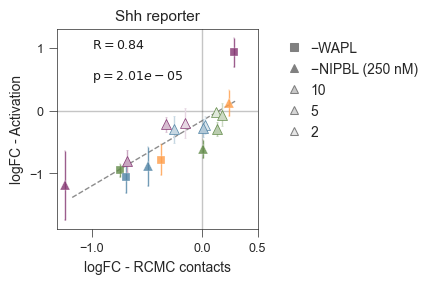

In [14]:
sns.set(
    style="ticks",
    font="Arial",
    rc={
        "axes.linewidth": 0.5,
        "xtick.major.width": 0.5,
        "ytick.major.width": 0.5,
        "xtick.minor.width": 0.5,
        "ytick.minor.width": 0.5,
    },
)

column1 = "log_FoldChange"
column2 = "log_FC"

df = mergefc
meandf = df.groupby(["Condition", "Region"]).mean().reset_index()
stddf = df.groupby(["Condition", "Region"]).std().reset_index()
plot_df = meandf.copy()
plot_df["yerr"] = stddf[column2]

site_palette = {
    "0": "#c1292e",
    "96": "#ff9d47",
    "206": "#628b48",
    "409": "#5083a5",
    "848": "#833471",
}

def get_color(region):
  key = str(region).replace("kb", "")
  return site_palette.get(key, "#000000")

full_dose = 250.0


def dose_opacity(dose):
  return np.log1p(dose) / np.log1p(full_dose)


def tint(color, opacity):
  return tuple(1 + (c - 1) * opacity for c in to_rgb(color))


plot_df["Depleted"] = plot_df["Condition"].apply(
    lambda x: "WAPL" if "WAPL" in x else "NIPBL"
)


def extract_dose(cond):
  if "WAPL" in cond:
    return np.nan
  if "-" in cond:
    return full_dose
  import re

  match = re.search(r"NIPBL(\d+)", cond)
  if match:
    return float(match.group(1))
  return full_dose


plot_df["Dose"] = plot_df["Condition"].apply(extract_dose)

fig, ax = plt.subplots(figsize=(3.63, 2.75))
ax.set_box_aspect(1)

nipbl = plot_df[plot_df["Depleted"] == "NIPBL"]
wapl = plot_df[plot_df["Depleted"] == "WAPL"]
partial_doses = sorted(nipbl.loc[nipbl["Dose"] < full_dose, "Dose"].unique())

for _, row in wapl.iterrows():
  c = get_color(row["Region"])
  ax.errorbar(
      x=row[column1],
      y=row[column2],
      yerr=row["yerr"],
      fmt="s",
      color=c,
      markeredgecolor="white",
      elinewidth=1,
      capsize=1,
      markersize=6,
      markeredgewidth=0.25,
      alpha=0.8,
      zorder=10,
  )

full_nipbl = nipbl[nipbl["Dose"] == full_dose]
for _, row in full_nipbl.iterrows():
  c = get_color(row["Region"])
  ax.errorbar(
      x=row[column1],
      y=row[column2],
      yerr=row["yerr"],
      fmt="^",
      color=c,
      markeredgecolor="white",
      elinewidth=1,
      capsize=1,
      markersize=7,
      markeredgewidth=0.25,
      alpha=0.8,
      zorder=10,
  )

for dose in partial_doses:
  subset = nipbl[nipbl["Dose"] == dose]
  for _, row in subset.iterrows():
    base_c = get_color(row["Region"])
    op = dose_opacity(dose)
    tinted_c = tint(base_c, op)
    ax.errorbar(
        x=row[column1],
        y=row[column2],
        yerr=row["yerr"],
        fmt="^",
        color=tinted_c,
        elinewidth=1,
        capsize=1,
        markersize=6.5,
        markeredgecolor=base_c,
        markeredgewidth=.5,
        zorder=11,
    )

xdata = meandf[column1]
ydata = meandf[column2]
popt, pcov = curve_fit(func_linear, xdata, ydata)
xspace = np.linspace(min(xdata) - min(xdata) / 20, max(xdata) + max(xdata) / 20)
ax.plot(xspace, func_linear(xspace, *popt), "k--", lw=1, zorder=-1, alpha=0.5)

ax.set_ylabel("logFC - Activation", fontsize=10)
ax.set_xlabel("logFC - RCMC contacts", fontsize=10)
ax.tick_params(labelsize=9)

ax.axhline(0, alpha=0.25, linewidth=1, color="k")
ax.axvline(0, alpha=0.25, linewidth=1, color="k")

prsn = pearsonr(xdata, ydata)
ax.text(-1, 1, rf"$\mathrm{{R}}={prsn[0]:.2f}$", fontsize=9, color="k")
ax.text(-1, 0.5, rf"$\mathrm{{p}}={prsn[1]:.2e}$", fontsize=9, color="k")
ax.set_title("Shh reporter", fontsize=11)

def handle(marker, opacity=1):
  return Line2D(
      [],
      [],
      marker=marker,
      linestyle="none",
      markersize=6,
      markeredgecolor="grey",
      markeredgewidth=0.75,
      markerfacecolor=tint("grey", opacity),
  )


handles = (
  [handle("s")] +
    [handle("^")]
    + [handle("^", dose_opacity(dose)) for dose in partial_doses[::-1]]
)
labels = (
    ["\u2212WAPL"]
    + [f"\u2212NIPBL ({int(full_dose)} nM)"]
    + [f"{int(dose)}" for dose in partial_doses[::-1]]
)

ax.legend(
    handles=handles,
    labels=labels,
    loc="upper left",
    bbox_to_anchor=(1.05, 1),
    frameon=False,
    fontsize=10,
    handletextpad=0.2,
)

plt.subplots_adjust(left=0.18, right=0.78, bottom=0.15, top=0.88)
plt.yticks([-1, 0, 1])
plt.xticks([-1, 0, 0.5])
#plt.savefig("Fig5D.svg", dpi=300)
#plt.show()

In [15]:
Shh_flow1 = pd.concat([
    pd.read_table("NIPBL_data_1.txt"),
    pd.read_table("NIPBL_data_3.txt"),
    pd.read_table("WAPL_data_1.txt"),
    pd.read_table("WAPL_data_3.txt"),
    ])
Shh_flow1 = Shh_flow1[Shh_flow1["treatment"].isin(["DMSO", "dTAG"])]
Shh_flow1["cell_line"] = np.where(Shh_flow1["cell_line"]=="dTAG-NIPBL", "NIPBL", "WAPL")
Shh_flow1["treatment"] = np.where(Shh_flow1["treatment"]=="dTAG", "-", "+")
Shh_flow1["sample"] = Shh_flow1["cell_line"] + Shh_flow1["treatment"]

Shh_flow2 = pd.concat([
    pd.read_table("NIPBL_data_2.txt"),
    pd.read_table("WAPL_data_2.txt"),
    ])
Shh_flow2 = Shh_flow2[Shh_flow2["dose"].isin([250, 0])]
Shh_flow2["dose"] = np.where(Shh_flow2["dose"]==250, "-", "+")
Shh_flow2["cell_line"] = np.where(Shh_flow2["cell_line"]=="dTAG-NIPBL", "NIPBL", "WAPL")
Shh_flow2["sample"] = Shh_flow2["cell_line"] + Shh_flow2["dose"]
Shh_flow = pd.concat([Shh_flow1, Shh_flow2]).rename(columns={"guide": "target_region"})

In [16]:
activation = pd.read_table("Activation_combined.txt")
activation["Enhancer"] = activation["Enhancer"].str.replace("kb", "", regex=False)

In [17]:
merged = v4c_data.rename(columns={"sample": "Condition", "target_region": "Enhancer"}).merge(activation.groupby(["Enhancer", "Condition"], as_index=False)["NormMFI"].mean(), on=["Enhancer", "Condition"])

In [18]:
fish = pd.read_table("../DNA_FISH/DNA_FISH_data_median_prop.txt")
fish["Distance"] = 1 - fish["Distance"]
fish_map = {
    "Shh-ZRS": "848",
    "Shh-SBE2": "409",
    "Shh-SBE6": "96"
}

# Keep only Shh-enhancer pairs (drops SBE2-ZRS, SBE6-ZRS)
fish["Enhancer"] = fish["Measurement"].map(fish_map)
fish = fish.dropna(subset=["Enhancer"])
merged = merged.merge(fish.groupby(["Enhancer", "Condition"], as_index=False)[["Distance", "Proportion"]].mean(),
                      on=["Enhancer", "Condition"])

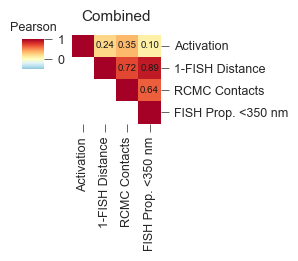

In [19]:
sns.set(style="ticks", font="Arial", rc={'figure.figsize':(1,1), "axes.linewidth": 0.5, 
                                         "xtick.major.width": 0.5, "ytick.major.width": 0.5,
                                         "xtick.minor.width": 0.5, "ytick.minor.width": 0.5})

corr = merged.loc[:, ["NormMFI", "Distance", "log_value", "Proportion"]].rename(columns={
    "Distance": "1-FISH Distance",
    "NormMFI": "Activation",
    "log_value": "RCMC Contacts",
    "Proportion": "FISH Prop. <350 nm",
}).corr(method="pearson")

g = sns.clustermap(corr, cmap="RdYlBu_r", vmin=-0.5, vmax=1, center=0, 
                   figsize=(3, 3), row_cluster=False, col_cluster=False)

mask = np.tril(np.ones_like(corr), k=-1)
values = g.ax_heatmap.collections[0].get_array().reshape(corr.shape)

g.ax_heatmap.set_title("Combined", fontsize=11, pad=10)

new_values = np.ma.array(values, mask=mask)
g.ax_heatmap.collections[0].set_array(new_values)

for i in range(corr.shape[0]):
    for j in range(corr.shape[1]):
        if not mask[i, j]:
            rval = corr.iloc[i, j]
            if rval < 1.0:
                g.ax_heatmap.text(j + 0.5, i + 0.5, f"{rval:.2f}",
                                  ha='center', va='center', color='k', fontsize=7)

g.ax_col_dendrogram.set_visible(False)
x0, _y0, _w, _h = g.cbar_pos
g.ax_heatmap.tick_params(axis='both', labelsize=9)

g.ax_cbar.set_position([x0-0.05, _y0-0.05, g.ax_row_dendrogram.get_position().width, 0.1])
g.ax_cbar.set_title('Pearson', size=9)
g.ax_cbar.tick_params(labelsize=9)

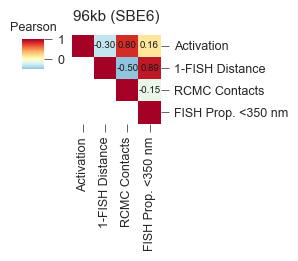

In [20]:
sns.set(style="ticks", font="Arial", rc={'figure.figsize':(1,1), "axes.linewidth": 0.5, 
                                         "xtick.major.width": 0.5, "ytick.major.width": 0.5,
                                         "xtick.minor.width": 0.5, "ytick.minor.width": 0.5})

corr = merged.loc[merged["Enhancer"]=="96", ["NormMFI", "Distance", "log_value", "Proportion"]].rename(columns={
    "Distance": "1-FISH Distance",
    "NormMFI": "Activation",
    "log_value": "RCMC Contacts",
    "Proportion": "FISH Prop. <350 nm",
}).corr(method="pearson")

g = sns.clustermap(corr, cmap="RdYlBu_r", vmin=-0.5, vmax=1, center=0, 
                   figsize=(3, 3), row_cluster=False, col_cluster=False)

mask = np.tril(np.ones_like(corr), k=-1)
values = g.ax_heatmap.collections[0].get_array().reshape(corr.shape)

g.ax_heatmap.set_title("96kb (SBE6)", fontsize=11, pad=10)

new_values = np.ma.array(values, mask=mask)
g.ax_heatmap.collections[0].set_array(new_values)

for i in range(corr.shape[0]):
    for j in range(corr.shape[1]):
        if not mask[i, j]:
            rval = corr.iloc[i, j]
            if rval < 1.0:
                g.ax_heatmap.text(j + 0.5, i + 0.5, f"{rval:.2f}",
                                  ha='center', va='center', color='k', fontsize=7)

g.ax_col_dendrogram.set_visible(False)
x0, _y0, _w, _h = g.cbar_pos
g.ax_heatmap.tick_params(axis='both', labelsize=9)

g.ax_cbar.set_position([x0-0.05, _y0-0.05, g.ax_row_dendrogram.get_position().width, 0.1])
g.ax_cbar.set_title('Pearson', size=9)
g.ax_cbar.tick_params(labelsize=9)

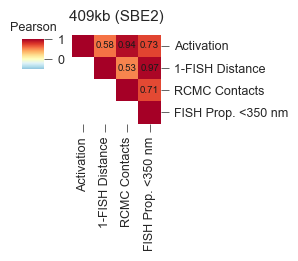

In [21]:
sns.set(style="ticks", font="Arial", rc={'figure.figsize':(1,1), "axes.linewidth": 0.5, 
                                         "xtick.major.width": 0.5, "ytick.major.width": 0.5,
                                         "xtick.minor.width": 0.5, "ytick.minor.width": 0.5})

corr = merged.loc[merged["Enhancer"]=="409", ["NormMFI", "Distance", "log_value", "Proportion"]].rename(columns={
    "Distance": "1-FISH Distance",
    "NormMFI": "Activation",
    "log_value": "RCMC Contacts",
    "Proportion": "FISH Prop. <350 nm",
}).corr(method="pearson")

g = sns.clustermap(corr, cmap="RdYlBu_r", vmin=-0.5, vmax=1, center=0, 
                   figsize=(3, 3), row_cluster=False, col_cluster=False)

mask = np.tril(np.ones_like(corr), k=-1)
values = g.ax_heatmap.collections[0].get_array().reshape(corr.shape)

g.ax_heatmap.set_title("409kb (SBE2)", fontsize=11, pad=10)

new_values = np.ma.array(values, mask=mask)
g.ax_heatmap.collections[0].set_array(new_values)

for i in range(corr.shape[0]):
    for j in range(corr.shape[1]):
        if not mask[i, j]:
            rval = corr.iloc[i, j]
            if rval < 1.0:
                g.ax_heatmap.text(j + 0.5, i + 0.5, f"{rval:.2f}",
                                  ha='center', va='center', color='k', fontsize=7)

g.ax_col_dendrogram.set_visible(False)
x0, _y0, _w, _h = g.cbar_pos
g.ax_heatmap.tick_params(axis='both', labelsize=9)

g.ax_cbar.set_position([x0-0.05, _y0-0.05, g.ax_row_dendrogram.get_position().width, 0.1])
g.ax_cbar.set_title('Pearson', size=9)
g.ax_cbar.tick_params(labelsize=9)

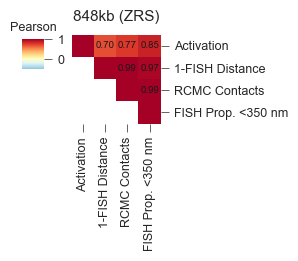

In [22]:
sns.set(style="ticks", font="Arial", rc={'figure.figsize':(1,1), "axes.linewidth": 0.5, 
                                         "xtick.major.width": 0.5, "ytick.major.width": 0.5,
                                         "xtick.minor.width": 0.5, "ytick.minor.width": 0.5})

corr = merged.loc[merged["Enhancer"]=="848", ["NormMFI", "Distance", "log_value", "Proportion"]].rename(columns={
    "Distance": "1-FISH Distance",
    "NormMFI": "Activation",
    "log_value": "RCMC Contacts",
    "Proportion": "FISH Prop. <350 nm",
}).corr(method="pearson")

g = sns.clustermap(corr, cmap="RdYlBu_r", vmin=-0.5, vmax=1, center=0, 
                   figsize=(3, 3), row_cluster=False, col_cluster=False)

mask = np.tril(np.ones_like(corr), k=-1)
values = g.ax_heatmap.collections[0].get_array().reshape(corr.shape)

g.ax_heatmap.set_title("848kb (ZRS)", fontsize=11, pad=10)

new_values = np.ma.array(values, mask=mask)
g.ax_heatmap.collections[0].set_array(new_values)

for i in range(corr.shape[0]):
    for j in range(corr.shape[1]):
        if not mask[i, j]:
            rval = corr.iloc[i, j]
            if rval < 1.0:
                g.ax_heatmap.text(j + 0.5, i + 0.5, f"{rval:.2f}",
                                  ha='center', va='center', color='k', fontsize=7)

g.ax_col_dendrogram.set_visible(False)
x0, _y0, _w, _h = g.cbar_pos
g.ax_heatmap.tick_params(axis='both', labelsize=9)

g.ax_cbar.set_position([x0-0.05, _y0-0.05, g.ax_row_dendrogram.get_position().width, 0.1])
g.ax_cbar.set_title('Pearson', size=9)
g.ax_cbar.tick_params(labelsize=9)